# Student Performance Data: Inspection, Cleaning, Analysis, and Scaling

**Task:** Analyze the provided student-performance dataset using pandas and NumPy, visualize relationships, calculate correlation and a dot product, and standardize selected features.

> **Reproducibility note:** The original dataset is generated below with the task's seed (`42`). The final-score formula is wrapped in parentheses to make the provided multi-line expression valid Python.


## Setup and create the provided dataset

Run this notebook from top to bottom. It only needs `pandas`, `numpy`, and `matplotlib`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_mark": previous_mark,
    "final_score": final_score
})

df.loc[0:5, "study_hours"] = np.nan  # Missing values
df.loc[99, "study_hours"] = 50       # Outlier
df.loc[98, "attendance"] = -10       # Impossible value

print("Original dataset shape:", df.shape)
display(df.head(10))
display(df.tail(3))


Original dataset shape: (100, 4)


,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
5,NaN,89.040509,55.932624,40.751177
6,8.158426,103.861859,77.725529,57.171201
7,6.534869,86.745778,77.706789,41.874669
8,4.061051,87.575504,77.725715,46.583807
9,6.085120,84.255541,127.790972,52.866454


,study_hours,attendance,previous_mark,final_score
97,5.522111,86.537251,74.609493,50.413491
98,5.010227,-10.000000,82.192932,44.045627
99,50.000000,73.570297,79.444433,46.414470


## Part A — Inspect and Clean

### A1. Identify and handle the outlier

The obvious outlier is **row/index 99**, where `study_hours = 50`. This is far above the usual study-hour values generated around a mean of 5 hours. Here, we **remove that record** rather than cap it, because the task explicitly identifies it as a dirty record and it could strongly distort summary statistics, plots, and correlation.

We also handle two other data-quality issues so the later analysis is reliable:
- The first six `study_hours` values are missing; fill them with the median of the non-missing study-hour values.
- `attendance = -10` at index 98 is impossible for an attendance percentage; treat it as missing and fill it with the median of valid attendance values.

The target `final_score` is not imputed or changed.


In [2]:
# Record the identified outlier before removing it
outlier_rows = df.loc[df["study_hours"] == 50, ["study_hours", "attendance", "previous_mark", "final_score"]]
print("Identified outlier row(s):")
display(outlier_rows)

clean_df = df.copy()

# Replace the impossible attendance value with missing, then impute it
clean_df.loc[clean_df["attendance"] < 0, "attendance"] = np.nan
clean_df["attendance"] = clean_df["attendance"].fillna(clean_df["attendance"].median())

# Impute missing study_hours with the median of available values
clean_df["study_hours"] = clean_df["study_hours"].fillna(clean_df["study_hours"].median())

# Remove the record with 50 study hours
clean_df = clean_df.loc[clean_df["study_hours"] != 50].copy()

print("Cleaned dataset shape:", clean_df.shape)
print("Missing values by column:")
display(clean_df.isna().sum().to_frame("missing_values"))
display(clean_df.describe().round(2))


Identified outlier row(s):


,study_hours,attendance,previous_mark,final_score
99,50.0,73.570297,79.444433,46.41447


Cleaned dataset shape: (99, 4)
Missing values by column:


,missing_values
study_hours,0
attendance,0
previous_mark,0
final_score,0


,study_hours,attendance,previous_mark,final_score
count,99.00,99.00,99.00,99.00
mean,4.74,85.34,70.89,42.65
std,1.78,9.51,16.32,6.11
min,-0.24,65.81,21.38,29.16
25%,3.80,77.07,60.14,38.13
50%,4.81,86.00,71.23,42.67
75%,5.72,90.54,80.84,46.78
max,8.70,112.20,127.79,57.17


### A2. Feature matrix shape, numerical columns, and target




In [3]:
feature_columns = ["study_hours", "attendance", "previous_mark"]
X = clean_df[feature_columns]
y = clean_df["final_score"]

print("Numerical columns:", clean_df.select_dtypes(include=np.number).columns.tolist())
print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)


Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Feature matrix X shape: (99, 3)
Target vector y shape: (99,)


## Part B — Summarize

### B1. Mean, median, and standard deviation for all columns

The following table uses the **cleaned dataset**. Standard deviation is pandas' sample standard deviation (`ddof=1`).


In [4]:
summary = clean_df.agg(["mean", "median", "std"]).T
summary = summary.rename(columns={"mean": "Mean", "median": "Median", "std": "Standard deviation"})
display(summary.round(3))


,Mean,Median,Standard deviation
study_hours,4.742,4.812,1.784
attendance,85.345,85.997,9.512
previous_mark,70.888,71.228,16.324
final_score,42.654,42.673,6.106


### B2. Three observations in plain English

Use the printed summary above to support these observations:

1. **Study hours:** The mean and median study hours are much closer after cleaning than they would be with the 50-hour outlier included. The median imputation also gives the six missing study-hour entries a typical value rather than dropping those students.
2. **Attendance:** The impossible value of −10 was corrected using the median of valid attendance values. Attendance is measured on a much larger numerical scale than study hours.
3. **Final score:** Final scores vary across students rather than being identical. Their spread (standard deviation) summarizes how far scores tend to vary around the mean; the histogram below shows the distribution more directly.

For a stronger submission, quote the actual mean/standard deviation values from the table when describing whether a spread is low or high.


## Part C — Visualize

### C1. Histogram of `final_score`


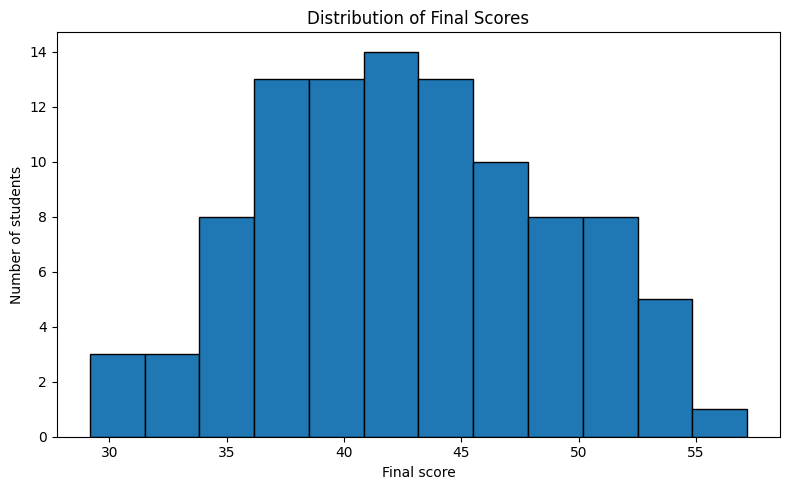

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(clean_df["final_score"], bins=12, edgecolor="black")
plt.xlabel("Final score")
plt.ylabel("Number of students")
plt.title("Distribution of Final Scores")
plt.tight_layout()
plt.show()


### C2. Scatter plot of `study_hours` versus `final_score`

Describe the trend after viewing the scatter plot. The generated score formula includes a positive contribution from study hours, so a **positive association is expected**, but the points will not lie exactly on a line because attendance, previous marks, and random noise also affect scores.


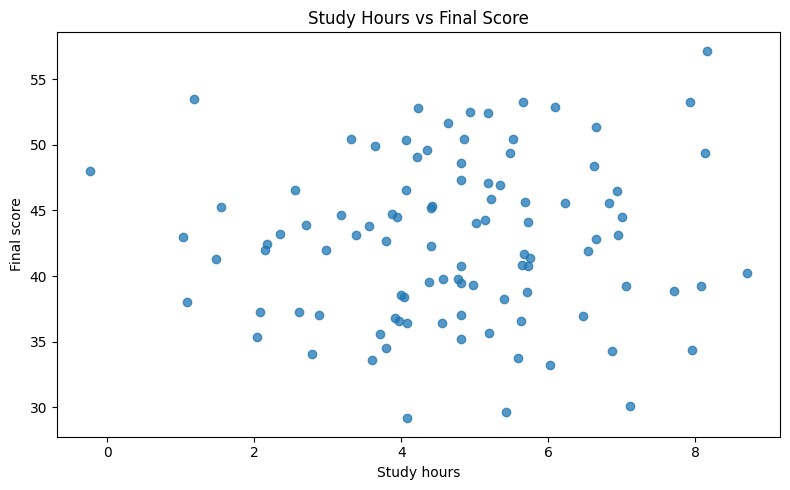

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["study_hours"], clean_df["final_score"], alpha=0.75)
plt.xlabel("Study hours")
plt.ylabel("Final score")
plt.title("Study Hours vs Final Score")
plt.tight_layout()
plt.show()


## Part D — Correlation and Causality

### D1. Pearson correlation coefficient

Pearson's \(r\) measures the strength and direction of a **linear association**. It ranges from −1 to +1. A positive value means higher study hours tend to be associated with higher final scores in this dataset.


In [7]:
pearson_r = clean_df["study_hours"].corr(clean_df["final_score"], method="pearson")
print(f"Pearson correlation (study_hours, final_score): {pearson_r:.4f}")


Pearson correlation (study_hours, final_score): 0.0496


### D2. Does studying 10 hours guarantee a specific score?

**No. Correlation does not guarantee an individual score.** It describes an overall pattern across observations; it is not a rule that uniquely determines a student's result. Two students who study 10 hours can receive different scores.

A possible **confounding (or lurking) variable** is **prior knowledge / previous academic performance** (`previous_mark`). A student with stronger prior knowledge may both study more effectively and earn a higher score. Attendance, sleep, teaching quality, and exam difficulty could also matter. Correlation alone does not prove that study time causes a particular score.


## Part E — Vectors and Dot Product

Choose one student row, using the three feature columns and excluding the target. The specified weight vector is \(\mathbf{w}=[0.5, 0.2, 0.4]\) and the bias is \(b=5\). Calculate \(\hat y = \mathbf{w}\cdot\mathbf{x}+b\) with NumPy.


In [8]:
# Select the first cleaned student row and exclude the target column
student = clean_df.iloc[0]
x = student[feature_columns].to_numpy(dtype=float)

w = np.array([0.5, 0.2, 0.4], dtype=float)
b = 5

y_hat = np.dot(w, x) + b

print("Selected student's feature vector x =", x)
print("Weight vector w =", w)
print("Bias b =", b)
print(f"Dot product w · x = {np.dot(w, x):.4f}")
print(f"Predicted value y_hat = w · x + b = {y_hat:.4f}")


Selected student's feature vector x = [ 4.8123416  70.84629258 75.36681041]
Weight vector w = [0.5 0.2 0.4]
Bias b = 5
Dot product w · x = 46.7222
Predicted value y_hat = w · x + b = 51.7222


### E4. What do the weights and bias mean?

- **Weights** represent how much each feature contributes to the model's calculated output, according to the model. A larger weight means a larger contribution for a one-unit increase in that feature when other features stay fixed. The units and scales of features matter when comparing weights.
- **Bias** is a constant offset added to the weighted sum. It lets the model predict a nonzero output even when all feature values are zero and allows the fitted relationship to shift up or down.

**Important:** These are the weights specified by the exercise, not weights learned from the dataset. The result is a demonstration of a linear-model calculation, not necessarily a well-calibrated real prediction.


## Part F — Scaling

### F1. Standardize `study_hours` and `previous_mark`

Use the requested formula \(z=(x-\mu)/\sigma\). Here, `ddof=0` is used for the standard deviation so the standardized columns have population standard deviation 1 on this dataset. If your instructor expects pandas' default sample standard deviation, use `ddof=1` instead.


In [9]:
scaled_df = clean_df.copy()

for column in ["study_hours", "previous_mark"]:
    mean_value = scaled_df[column].mean()
    std_value = scaled_df[column].std(ddof=0)
    scaled_df[column + "_z"] = (scaled_df[column] - mean_value) / std_value

print("Original ranges:")
display(clean_df[["study_hours", "previous_mark"]].agg(["min", "max"]).round(3))

print("Means and population standard deviations after scaling (approximately 0 and 1):")
display(scaled_df[["study_hours_z", "previous_mark_z"]].agg(["mean", "std"]).round(4))

display(scaled_df[["study_hours", "study_hours_z", "previous_mark", "previous_mark_z"]].head())


Original ranges:


,study_hours,previous_mark
min,-0.239,21.381
max,8.705,127.791


Means and population standard deviations after scaling (approximately 0 and 1):


,study_hours_z,previous_mark_z
mean,0.0000,0.0000
std,1.0051,1.0051


,study_hours,study_hours_z,previous_mark,previous_mark_z
0,4.812342,0.039665,75.366810,0.275767
1,4.812342,0.039665,78.411768,0.463245
2,4.812342,0.039665,86.245769,0.945583
3,4.812342,0.039665,85.807031,0.918570
4,4.812342,0.039665,49.334959,-1.327010


### F2. Why does K-Nearest Neighbors need scaling?

K-Nearest Neighbors commonly uses a distance measure such as Euclidean distance. Before scaling, `previous_mark` spans a much wider numerical range than `study_hours` (which is measured in hours). Consequently, differences in previous marks can dominate the distance calculation, even if study hours are also useful. Standardization puts both features on comparable scales so neither dominates merely because its units or range are larger.


